In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install pyspark -q

Mounted at /content/drive


In [2]:
!pip install -q graphframes-py==0.12.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.5/73.5 kB 2.5 MB/s eta 0:00:00


In [3]:
from pyspark.sql import SparkSession
from pathlib import Path

spark = (
    SparkSession.builder
    .appName("NYC Taxi Analysis_2")
    .config(
        "spark.jars.packages",
        "io.graphframes:graphframes-spark4_2.13:0.12.2"
    )
    .getOrCreate()
)

In [4]:
import os
import pandas as pd
from pyspark.sql import functions as F

FIGURE_DIR = "/content/drive/MyDrive/MIT805/Group Project/Figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

In [5]:
df_working_dataset = spark.read.parquet(
    "/content/drive/MyDrive/MIT805/Group Project/ProcessedData/CleanedData"
)
df_working_dataset.show(5)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|vendorid|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|ratecodeid|store_and_fwd_flag|pulocationid|dolocationid|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|       1| 2016-01-01 00:12:22|  2016-01-01 00:29:14|            1.0|          3.2|         1|                 N|          48|    

In [6]:
from pyspark.sql.functions import col

df = df_working_dataset.filter(
    (col("tpep_pickup_datetime") >= "2021-01-01 00:00:00")
)

df.show(5)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|vendorid|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|ratecodeid|store_and_fwd_flag|pulocationid|dolocationid|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|       2| 2026-02-13 11:06:18|  2026-02-13 18:26:09|            2.0|         3.14|         1|                 N|         163|    

In [7]:
df = (
    df

    # ---------------------------------------------------------
    # 1. Calculate trip duration in minutes
    # ---------------------------------------------------------
    .withColumn(
        "duration_minutes",
        (
            F.unix_timestamp(F.col("tpep_dropoff_datetime"))
            - F.unix_timestamp(F.col("tpep_pickup_datetime"))
        ) / 60
    )

    # ---------------------------------------------------------
    # 2. Driver revenue proxy
    #    fare + extra + recorded tips
    # ---------------------------------------------------------
    .withColumn(
        "driver_revenue",
        F.coalesce(F.col("fare_amount"), F.lit(0.0))
        + F.coalesce(F.col("extra"), F.lit(0.0))
        + F.coalesce(F.col("tip_amount"), F.lit(0.0))
    )

    # ---------------------------------------------------------
    # 4. Driver revenue per minute
    # ---------------------------------------------------------
    .withColumn(
        "driver_revenue_per_minute",
        F.when(
            F.col("duration_minutes") > 0,
            F.col("driver_revenue") / F.col("duration_minutes")
        )
    )
)
df.show(5)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+-----------------+--------------+-------------------------+
|vendorid|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|ratecodeid|store_and_fwd_flag|pulocationid|dolocationid|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|cbd_congestion_fee| duration_minutes|driver_revenue|driver_revenue_per_minute|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+-------------

In [17]:
from pyspark.sql import functions as F

df_filtered = (
    df
    .filter(
        (F.col("duration_minutes") < 1200) & (F.col("duration_minutes") >= 0) &
        (F.col("trip_distance") < 100)
    )
)


In [ ]:
ratecode_revenue = (
    df_filtered
    .filter(
        F.col("RatecodeID").isNotNull() &
        F.col("driver_revenue_per_minute").isNotNull()
    )
    .withColumn(
        "rate_code_name",
        F.when(F.col("RatecodeID") == 1, "Standard rate")
         .when(F.col("RatecodeID") == 2, "JFK")
         .when(F.col("RatecodeID") == 3, "Newark")
         .when(F.col("RatecodeID") == 4, "Nassau or Westchester")
         .when(F.col("RatecodeID") == 5, "Negotiated fare")
         .when(F.col("RatecodeID") == 6, "Group ride")
         .when(F.col("RatecodeID") == 99, "Null/unknown")
         .otherwise("Other/unknown")
    )
    .groupBy("RatecodeID", "rate_code_name")
    .agg(
        F.count("*").alias("trip_count"),
        F.avg("driver_revenue_per_minute").alias(
            "avg_driver_revenue_per_minute"
        )
    )
    .orderBy(F.desc("avg_driver_revenue_per_minute"))
)

ratecode_revenue.show(truncate=False)

+----------+---------------------+----------+-----------------------------+
|RatecodeID|rate_code_name       |trip_count|avg_driver_revenue_per_minute|
+----------+---------------------+----------+-----------------------------+
|5         |Negotiated fare      |3171692   |343.16980628791976           |
|6         |Group ride           |1488      |167.04976623807147           |
|3         |Newark               |1250064   |11.896499127907411           |
|2         |JFK                  |13573960  |11.84577385021513            |
|4         |Nassau or Westchester|837550    |2.8514439512039216           |
|99        |Null/unknown         |53732010  |2.0123986991628997           |
|1         |Standard rate        |360825870 |1.616318783143034            |
+----------+---------------------+----------+-----------------------------+



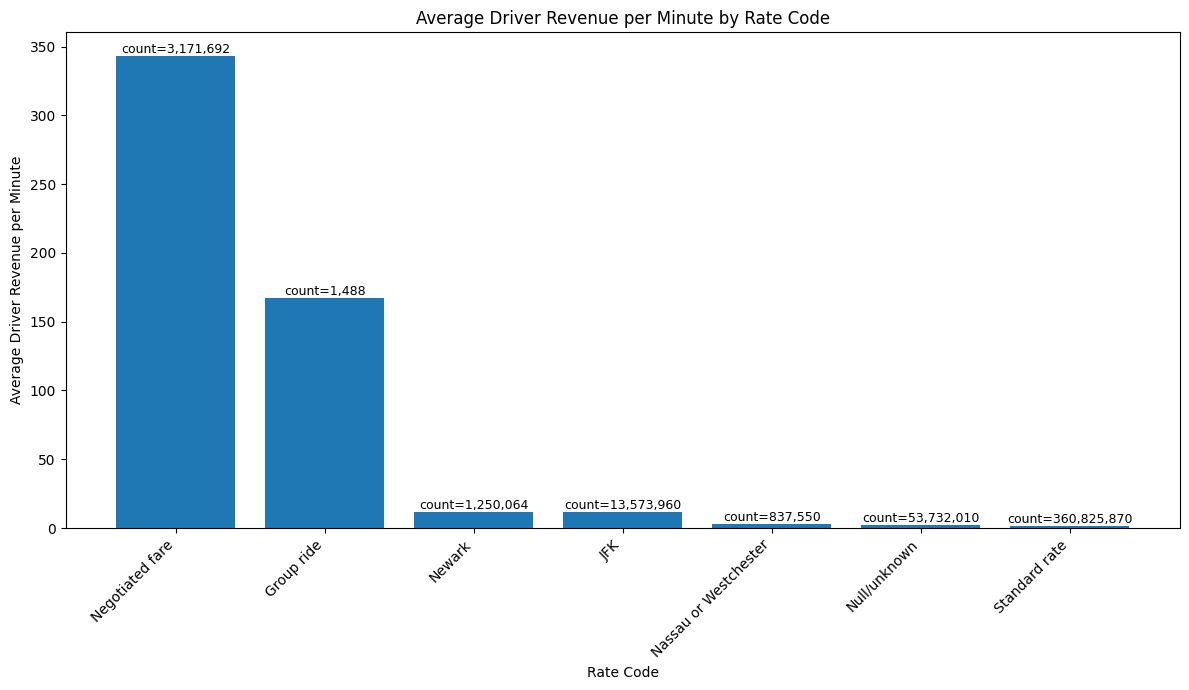

In [ ]:
import matplotlib.pyplot as plt

# Convert the small aggregated result to Pandas
ratecode_pd = ratecode_revenue.toPandas()

# Plot
plt.figure(figsize=(12, 7))

bars = plt.bar(
    ratecode_pd["rate_code_name"],
    ratecode_pd["avg_driver_revenue_per_minute"]
)

plt.xlabel("Rate Code")
plt.ylabel("Average Driver Revenue per Minute")
plt.title("Average Driver Revenue per Minute by Rate Code")
plt.xticks(rotation=45, ha="right")

# Add trip count above each bar
for bar, count in zip(bars, ratecode_pd["trip_count"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"count={count:,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Average_Driver_Revenue_per_Minute_by_RatecodeID.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
spark.sparkContext.uiWebUrl

'http://d32c826ca9af:4040'

In [ ]:
spark.sparkContext.getConf().get("spark.ui.port")

In [ ]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Calculate average fare amount per minute by payment type
payment_fare_per_minute = (
    df_filtered
    .filter(
        F.col("payment_type").isNotNull() &
        F.col("fare_amount").isNotNull() &
        F.col("duration_minutes").isNotNull() &
        (F.col("duration_minutes") > 0)
    )
    .withColumn(
        "payment_type_name",
        F.when(F.col("payment_type") == 0, "Flex Fare")
         .when(F.col("payment_type") == 1, "Credit card")
         .when(F.col("payment_type") == 2, "Cash")
         .when(F.col("payment_type") == 3, "No charge")
         .when(F.col("payment_type") == 4, "Dispute")
         .when(F.col("payment_type") == 5, "Unknown")
         .when(F.col("payment_type") == 6, "Voided trip")
         .otherwise("Other")
    )
    .withColumn(
        "fare_per_minute",
        F.col("fare_amount") / F.col("duration_minutes")
    )
    .groupBy("payment_type", "payment_type_name")
    .agg(
        F.count("*").alias("trip_count"),
        F.avg("fare_per_minute").alias("avg_fare_per_minute")
    )
    .orderBy(F.desc("avg_fare_per_minute"))
)

payment_fare_per_minute.show(truncate=False)

+------------+-----------------+----------+--------------------+
|payment_type|payment_type_name|trip_count|avg_fare_per_minute |
+------------+-----------------+----------+--------------------+
|1           |Credit card      |310816826 |4.219589052664637   |
|2           |Cash             |65033204  |3.425864904908334   |
|3           |No charge        |2490970   |3.2199600900377345  |
|0           |Flex Fare        |49211160  |1.6531811379003232  |
|5           |Unknown          |22        |0.4034130567061965  |
|4           |Dispute          |5840452   |-0.34490975736240165|
+------------+-----------------+----------+--------------------+



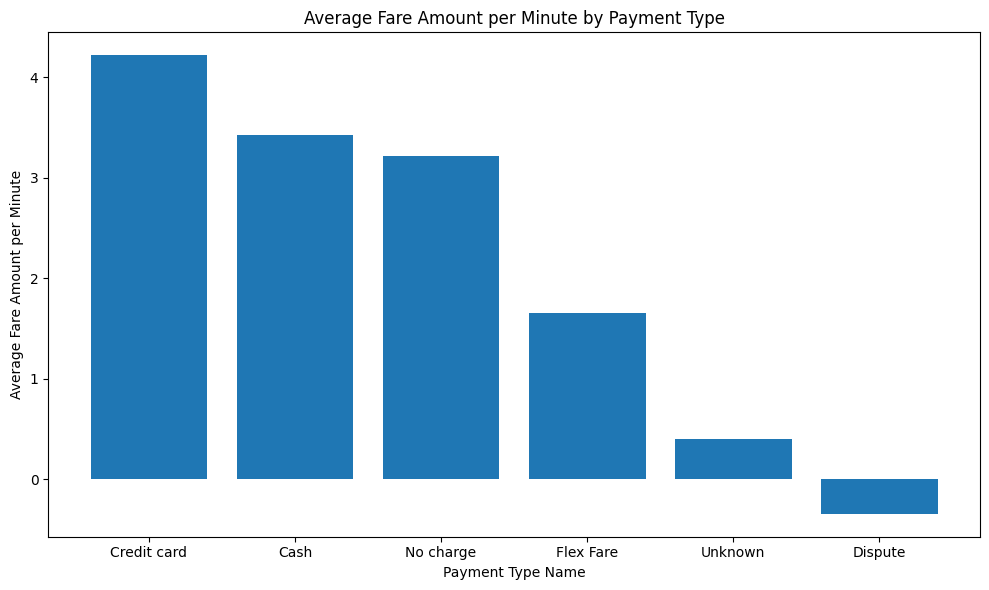

In [ ]:
# Convert the small aggregated result to Pandas
payment_fare_per_minute_pd = payment_fare_per_minute.toPandas()

# Plot
plt.figure(figsize=(10, 6))

plt.bar(
    payment_fare_per_minute_pd["payment_type_name"].astype(str),
    payment_fare_per_minute_pd["avg_fare_per_minute"]
)

plt.xlabel("Payment Type Name")
plt.ylabel("Average Fare Amount per Minute")
plt.title("Average Fare Amount per Minute by Payment Type")
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURE_DIR, "Average_Fare_Amount_per_minute_by_Payment_Type.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
payment_fare_per_minute.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (22)
+- == Final Plan ==
   ResultQueryStage (14)
   +- * Sort (13)
      +- AQEShuffleRead (12)
         +- ShuffleQueryStage (11), Statistics(sizeInBytes=144.0 B, rowCount=6)
            +- Exchange (10)
               +- * HashAggregate (9)
                  +- AQEShuffleRead (8)
                     +- ShuffleQueryStage (7), Statistics(sizeInBytes=17.6 KiB, rowCount=564)
                        +- Exchange (6)
                           +- * HashAggregate (5)
                              +- * Project (4)
                                 +- * Filter (3)
                                    +- * ColumnarToRow (2)
                                       +- Scan parquet  (1)
+- == Initial Plan ==
   Sort (21)
   +- Exchange (20)
      +- HashAggregate (19)
         +- Exchange (18)
            +- HashAggregate (17)
               +- Project (16)
                  +- Filter (15)
                     +- Scan parquet  (1)


(1) Scan parquet 
Output [5]

In [10]:
# Create distance bins and calculate average revenue
revenue_by_distance = (
    df_filtered
    .withColumn(
        "distance_bin",
        (F.floor(F.col("trip_distance") / 5) * 5)
    )
    .groupBy("distance_bin")
    .agg(
        F.avg("driver_revenue").alias("avg_revenue"),
        F.count("*").alias("trip_count")
    )
    .orderBy("distance_bin")
)

# Convert only the small aggregated result to Pandas
revenue_by_distance_pd = revenue_by_distance.toPandas()

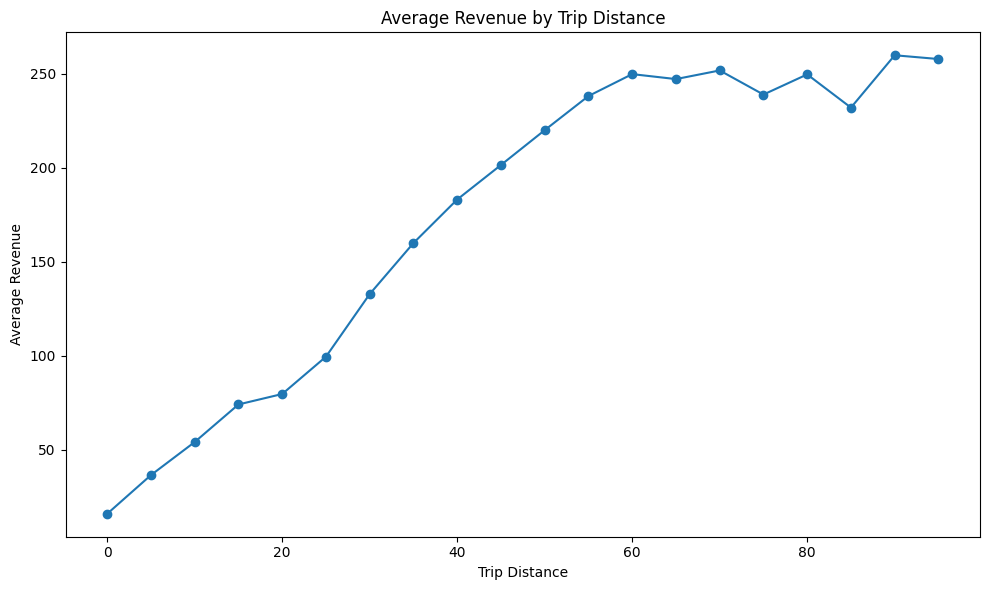

<Figure size 640x480 with 0 Axes>

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    revenue_by_distance_pd["distance_bin"],
    revenue_by_distance_pd["avg_revenue"],
    marker="o"
)

plt.xlabel("Trip Distance")
plt.ylabel("Average Revenue")
plt.title("Average Revenue by Trip Distance")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "Average_Revenue_by_Distance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.savefig(
    os.path.join(FIGURE_DIR, "Average_Revenue_by_Duration.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
revenue_by_duration = (
    df_filtered
    .withColumn(
        "duration_bin",
        (F.floor(F.col("duration_minutes") / 10) * 10)
    )
    .groupBy("duration_bin")
    .agg(
        F.avg("driver_revenue").alias("avg_revenue"),
        F.count("*").alias("trip_count")
    )
    .orderBy("duration_bin")
)

# Convert only the aggregated result
revenue_by_duration_pd = revenue_by_duration.toPandas()

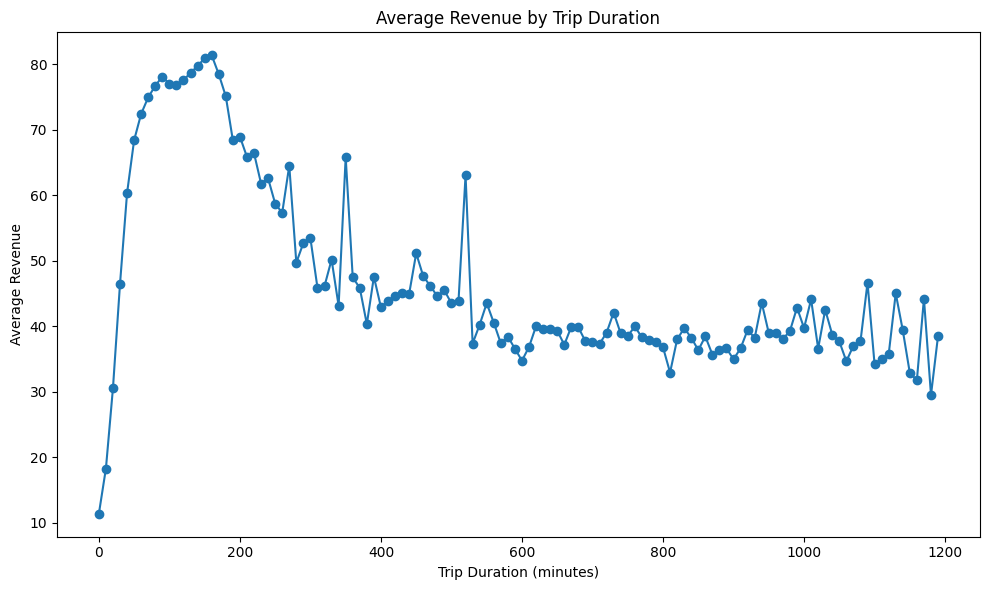

In [19]:
plt.figure(figsize=(10, 6))

plt.plot(
    revenue_by_duration_pd["duration_bin"],
    revenue_by_duration_pd["avg_revenue"],
    marker="o"
)

plt.xlabel("Trip Duration (minutes)")
plt.ylabel("Average Revenue")
plt.title("Average Revenue by Trip Duration")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "Average_Revenue_by_Duration.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()